In [ ]:
import pandas as pd

# Read the dataset
df = pd.read_csv('/content/train-test.csv')

# Display basic information and shape
print(f"Dataset Shape: {df.shape}")
print(df.head())

Dataset Shape: (48000, 14)
     load_id        pickup      delivery  pickup_lat  pickup_lon  \
0  TR-000001      Richmond     Baltimore    38.09122   -76.78906   
1  TR-000002      Richmond  Philadelphia    38.09122   -76.78906   
2  TR-000003  Philadelphia     Green Bay    39.22317   -72.96710   
3  TR-000004      Hartford       Atlanta    39.55328   -72.18051   
4  TR-000005        Dallas     Nashville    31.83025   -94.38343   

   delivery_lat  delivery_lon  distance equipment   weight        date  \
0      38.16908     -72.74564     274.3   Dry Van  30658.0  2025-01-01   
1      39.22317     -72.96710     280.5    Reefer  17555.0  2025-01-01   
2      44.30296     -87.52871     967.8   Dry Van  31721.0  2025-01-01   
3      34.84933     -86.28940     965.4   Dry Van  32333.0  2025-01-01   
4      35.29479     -88.08915     541.9    Reefer  35183.0  2025-01-01   

   market_index  quote_signal  posted_rate  
0       0.95684       2.39595       645.41  
1       0.97623       2.43355

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


In [ ]:
# Calculate medians
weight_median = df['weight'].median()
market_index_median = df['market_index'].median()

# Impute missing values
df['weight'] = df['weight'].fillna(weight_median)
df['market_index'] = df['market_index'].fillna(market_index_median)

# Verify that there are no missing values remaining
print(df[['weight', 'market_index']].isnull().sum())

weight          0
market_index    0
dtype: int64


In [ ]:
# Identify numeric columns
numeric_cols = ['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate']

# Calculate IQR and filter outliers
initial_rows = len(df)
mask = pd.Series(True, index=df.index)

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep track of rows within valid bounds for each column
    mask = mask & (df[col] >= lower_bound) & (df[col] <= upper_bound)

# Filter the DataFrame
df_clean = df[mask].copy()
removed_rows = initial_rows - len(df_clean)

print(f"Original dataset size: {initial_rows}")
print(f"Cleaned dataset size: {len(df_clean)}")
print(f"Removed {removed_rows} outlier rows ({removed_rows / initial_rows * 100:.2f}% of the data).")

Original dataset size: 48000
Cleaned dataset size: 45353
Removed 2647 outlier rows (5.51% of the data).


In [ ]:
# Identify all numeric columns in the dataframe
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
print(f"Numeric columns to check for outliers: {numeric_cols}")

initial_rows = len(df)
mask = pd.Series(True, index=df.index)

# Calculate IQR and filter outliers for each numeric column
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Keep track of rows within valid bounds for each column
    mask = mask & (df[col] >= lower_bound) & (df[col] <= upper_bound)

# Filter the DataFrame in-place/overwrite
df = df[mask].copy()
removed_rows = initial_rows - len(df)

print(f"\nOriginal dataset size: {initial_rows}")
print(f"Cleaned dataset size: {len(df)}")
print(f"Removed {removed_rows} outlier rows ({removed_rows / initial_rows * 100:.2f}% of the data).")

Numeric columns to check for outliers: ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'weight', 'market_index', 'quote_signal', 'posted_rate']

Original dataset size: 48000
Cleaned dataset size: 44472
Removed 3528 outlier rows (7.35% of the data).


In [ ]:
# Show updated dataframe structure and information
print("=== Dataset Information ===")
df.info()

print("\n=== Summary Statistics ===")
print(df.describe().T)

print("\n=== First 5 Rows of Cleaned Dataset ===")
print(df.head())

=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
Index: 44472 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       44472 non-null  object 
 1   pickup        44472 non-null  object 
 2   delivery      44472 non-null  object 
 3   pickup_lat    44472 non-null  float64
 4   pickup_lon    44472 non-null  float64
 5   delivery_lat  44472 non-null  float64
 6   delivery_lon  44472 non-null  float64
 7   distance      44472 non-null  float64
 8   equipment     44472 non-null  object 
 9   weight        44472 non-null  float64
 10  date          44472 non-null  object 
 11  market_index  44472 non-null  float64
 12  quote_signal  44472 non-null  float64
 13  posted_rate   44472 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB

=== Summary Statistics ===
                count          mean          std         min           25%  \
pickup_lat    44472.0 

In [ ]:
# Convert date column to datetime
df['date'] = pd.to_datetime(df['date'])

# Sort the dataset chronologically
df = df.sort_values(by='date').reset_index(drop=True)
df.head(20)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000108,Philadelphia,St. Louis,39.22317,-72.96710,38.38204,-89.88819,1085.4,Dry Van,15712.0,2025-01-01,0.95874,1.78353,1958.10
2,TR-000107,San Antonio,Fort Wayne,29.50969,-98.40059,41.31561,-85.36206,1266.0,Flatbed,20678.0,2025-01-01,0.98745,1.99624,2498.90
3,TR-000106,Bakersfield,Milwaukee,33.28832,-116.67935,39.62180,-88.48008,1901.5,Dry Van,31374.0,2025-01-01,0.93499,1.81931,3407.03
4,TR-000105,Oklahoma City,Cincinnati,31.88294,-98.58097,37.15706,-86.77499,929.3,Dry Van,30918.0,2025-01-01,0.96079,1.91336,1792.83
5,TR-000104,Baton Rouge,Chattanooga,30.50134,-92.65374,35.29792,-87.18651,523.3,Dry Van,17804.0,2025-01-01,0.95108,2.05740,1074.67
6,TR-000103,Oklahoma City,Baton Rouge,31.88294,-98.58097,30.50134,-92.65374,418.0,Dry Van,31909.0,2025-01-01,0.94122,2.33556,970.69
7,TR-000102,New York,Houston,40.00674,-73.79840,30.71157,-94.76550,1556.3,Flatbed,28505.0,2025-01-01,0.92364,1.93531,3007.13
8,TR-000101,Oklahoma City,Cincinnati,31.88294,-98.58097,37.15706,-86.77499,900.3,Reefer,42482.0,2025-01-01,0.93478,2.30920,2101.86
9,TR-000100,Indianapolis,New York,38.52567,-88.85948,40.00674,-73.79840,932.8,Dry Van,37005.0,2025-01-01,0.99201,1.90185,1792.75


In [ ]:
df['date'].nunique()

304

In [ ]:
# Show the minimum, maximum, and unique count of dates
min_date = df['date'].min()
max_date = df['date'].max()
unique_dates = df['date'].nunique()

print(f"Earliest Date: {min_date}")
print(f"Latest Date: {max_date}")
print(f"Total Unique Dates: {unique_dates}")

# Display the top 10 rows showcasing the sorted dates
print("\nFirst 10 dates in the dataset:")
print(df['date'].head(10))

print("\nLast 10 dates in the dataset:")
print(df['date'].tail(10))

Earliest Date: 2025-01-01 00:00:00
Latest Date: 2025-10-31 00:00:00
Total Unique Dates: 304

First 10 dates in the dataset:
0   2025-01-01
1   2025-01-01
2   2025-01-01
3   2025-01-01
4   2025-01-01
5   2025-01-01
6   2025-01-01
7   2025-01-01
8   2025-01-01
9   2025-01-01
Name: date, dtype: datetime64[ns]

Last 10 dates in the dataset:
44462   2025-10-31
44463   2025-10-31
44464   2025-10-31
44465   2025-10-31
44466   2025-10-31
44467   2025-10-31
44468   2025-10-31
44469   2025-10-31
44470   2025-10-31
44471   2025-10-31
Name: date, dtype: datetime64[ns]


In [ ]:
import matplotlib.pyplot as plt

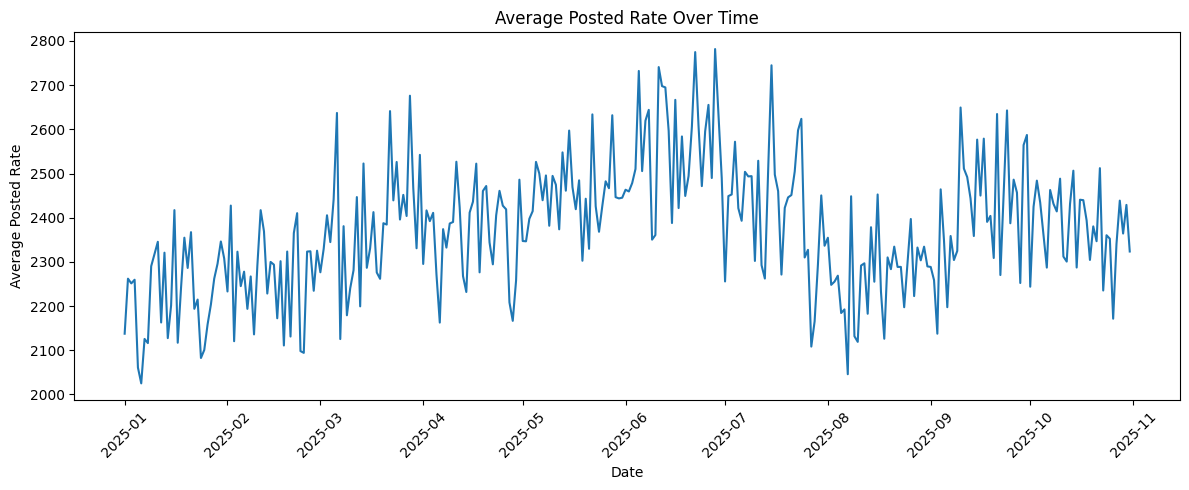

In [ ]:
daily_rate = (
    df.groupby('date')['posted_rate']
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(daily_rate['date'], daily_rate['posted_rate'])

plt.xlabel('Date')
plt.ylabel('Average Posted Rate')
plt.title('Average Posted Rate Over Time')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df.head(15)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000108,Philadelphia,St. Louis,39.22317,-72.96710,38.38204,-89.88819,1085.4,Dry Van,15712.0,2025-01-01,0.95874,1.78353,1958.10
2,TR-000107,San Antonio,Fort Wayne,29.50969,-98.40059,41.31561,-85.36206,1266.0,Flatbed,20678.0,2025-01-01,0.98745,1.99624,2498.90
3,TR-000106,Bakersfield,Milwaukee,33.28832,-116.67935,39.62180,-88.48008,1901.5,Dry Van,31374.0,2025-01-01,0.93499,1.81931,3407.03
4,TR-000105,Oklahoma City,Cincinnati,31.88294,-98.58097,37.15706,-86.77499,929.3,Dry Van,30918.0,2025-01-01,0.96079,1.91336,1792.83
5,TR-000104,Baton Rouge,Chattanooga,30.50134,-92.65374,35.29792,-87.18651,523.3,Dry Van,17804.0,2025-01-01,0.95108,2.05740,1074.67
6,TR-000103,Oklahoma City,Baton Rouge,31.88294,-98.58097,30.50134,-92.65374,418.0,Dry Van,31909.0,2025-01-01,0.94122,2.33556,970.69
7,TR-000102,New York,Houston,40.00674,-73.79840,30.71157,-94.76550,1556.3,Flatbed,28505.0,2025-01-01,0.92364,1.93531,3007.13
8,TR-000101,Oklahoma City,Cincinnati,31.88294,-98.58097,37.15706,-86.77499,900.3,Reefer,42482.0,2025-01-01,0.93478,2.30920,2101.86
9,TR-000100,Indianapolis,New York,38.52567,-88.85948,40.00674,-73.79840,932.8,Dry Van,37005.0,2025-01-01,0.99201,1.90185,1792.75


In [ ]:
df["date"].max()

Timestamp('2025-10-31 00:00:00')

In [ ]:
# Create year-month column
df["year_month"] = df["date"].dt.to_period("M")

# Get all months in order
months = sorted(df["year_month"].unique())

print("Months:")
for month in months:
    print(month)

Months:
2025-01
2025-02
2025-03
2025-04
2025-05
2025-06
2025-07
2025-08
2025-09
2025-10


In [ ]:
monthly_counts = df.groupby("year_month").size()

print(monthly_counts)

year_month
2025-01    4671
2025-02    4098
2025-03    4637
2025-04    4522
2025-05    4486
2025-06    4163
2025-07    4551
2025-08    4607
2025-09    4265
2025-10    4472
Freq: M, dtype: int64


In [ ]:
for i in range(1, len(months)):

    train_months = months[:i]
    validation_month = months[i]

    train_data = df[
        df["year_month"].isin(train_months)
    ]

    validation_data = df[
        df["year_month"] == validation_month
    ]

    print("Train:", train_months)
    print("Validation:", validation_month)
    print("Train rows:", len(train_data))
    print("Validation rows:", len(validation_data))
    print("-" * 50)

Train: [Period('2025-01', 'M')]
Validation: 2025-02
Train rows: 4671
Validation rows: 4098
--------------------------------------------------
Train: [Period('2025-01', 'M'), Period('2025-02', 'M')]
Validation: 2025-03
Train rows: 8769
Validation rows: 4637
--------------------------------------------------
Train: [Period('2025-01', 'M'), Period('2025-02', 'M'), Period('2025-03', 'M')]
Validation: 2025-04
Train rows: 13406
Validation rows: 4522
--------------------------------------------------
Train: [Period('2025-01', 'M'), Period('2025-02', 'M'), Period('2025-03', 'M'), Period('2025-04', 'M')]
Validation: 2025-05
Train rows: 17928
Validation rows: 4486
--------------------------------------------------
Train: [Period('2025-01', 'M'), Period('2025-02', 'M'), Period('2025-03', 'M'), Period('2025-04', 'M'), Period('2025-05', 'M')]
Validation: 2025-06
Train rows: 22414
Validation rows: 4163
--------------------------------------------------
Train: [Period('2025-01', 'M'), Period('2025-02

In [ ]:
target = "posted_rate"

In [ ]:
# Features
features = [
    col for col in df.columns
    if col not in [target, "date", "year_month","load_id"]
]

print("Features:")
print(features)

Features:
['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'market_index', 'quote_signal']


In [ ]:
!pip install catboost

In [ ]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

results = []

for i in range(1, len(months)):

    # -------------------------
    # Train / Validation split
    # -------------------------
    train_months = months[:i]
    validation_month = months[i]

    train_data = df[
        df["year_month"].isin(train_months)
    ].copy()

    validation_data = df[
        df["year_month"] == validation_month
    ].copy()

    # -------------------------
    # X / y
    # -------------------------
    X_train = train_data[features]
    y_train = train_data[target]

    X_val = validation_data[features]
    y_val = validation_data[target]

    # -------------------------
    # Model
    # -------------------------
    model = CatBoostRegressor(
        iterations=2000,
        learning_rate=0.06,
        depth=5,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    # -------------------------
    # Train
    # -------------------------
    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    # -------------------------
    # Prediction
    # -------------------------
    predictions = model.predict(X_val)

    # -------------------------
    # Metrics
    # -------------------------
    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    results.append({
        "train_until": train_months[-1],
        "validation_month": validation_month,
        "train_rows": len(train_data),
        "validation_rows": len(validation_data),
        "RMSE": rmse,
        "MAE": mae
    })

    print(
        f"Train until {train_months[-1]} "
        f"→ Validate {validation_month} | "
        f"RMSE: {rmse:.2f} | "
        f"MAE: {mae:.2f}"
    )

Train until 2025-01 → Validate 2025-02 | RMSE: 250.47 | MAE: 78.21
Train until 2025-02 → Validate 2025-03 | RMSE: 283.83 | MAE: 105.69
Train until 2025-03 → Validate 2025-04 | RMSE: 588.57 | MAE: 377.23
Train until 2025-04 → Validate 2025-05 | RMSE: 240.61 | MAE: 75.25
Train until 2025-05 → Validate 2025-06 | RMSE: 304.19 | MAE: 144.75
Train until 2025-06 → Validate 2025-07 | RMSE: 245.37 | MAE: 74.70
Train until 2025-07 → Validate 2025-08 | RMSE: 234.60 | MAE: 86.83
Train until 2025-08 → Validate 2025-09 | RMSE: 261.14 | MAE: 124.50
Train until 2025-09 → Validate 2025-10 | RMSE: 268.08 | MAE: 105.80


In [ ]:
results_df = pd.DataFrame(results)

print(results_df)

  train_until validation_month  train_rows  validation_rows        RMSE  \
0     2025-01          2025-02        4671             4098  250.469698   
1     2025-02          2025-03        8769             4637  283.832973   
2     2025-03          2025-04       13406             4522  588.573373   
3     2025-04          2025-05       17928             4486  240.613272   
4     2025-05          2025-06       22414             4163  304.191027   
5     2025-06          2025-07       26577             4551  245.368785   
6     2025-07          2025-08       31128             4607  234.600364   
7     2025-08          2025-09       35735             4265  261.143895   
8     2025-09          2025-10       40000             4472  268.078338   

          MAE  
0   78.211944  
1  105.686061  
2  377.232412  
3   75.249926  
4  144.751877  
5   74.702964  
6   86.826982  
7  124.502437  
8  105.799796  


**test on days**

In [ ]:
df["day"] = df["date"].dt.date

days = sorted(df["day"].unique())

print("Number of days:", len(days))
print(days[:10])

Number of days: 304
[datetime.date(2025, 1, 1), datetime.date(2025, 1, 2), datetime.date(2025, 1, 3), datetime.date(2025, 1, 4), datetime.date(2025, 1, 5), datetime.date(2025, 1, 6), datetime.date(2025, 1, 7), datetime.date(2025, 1, 8), datetime.date(2025, 1, 9), datetime.date(2025, 1, 10)]


In [ ]:
daily_counts = df.groupby("day").size()

print(daily_counts.head(20))
print("\nAverage rows per day:", daily_counts.mean())

day
2025-01-01    139
2025-01-02    159
2025-01-03    149
2025-01-04    149
2025-01-05    145
2025-01-06    157
2025-01-07    154
2025-01-08    180
2025-01-09    137
2025-01-10    165
2025-01-11    144
2025-01-12    149
2025-01-13    152
2025-01-14    156
2025-01-15    138
2025-01-16    140
2025-01-17    150
2025-01-18    154
2025-01-19    149
2025-01-20    146
dtype: int64

Average rows per day: 146.28947368421052


In [ ]:
results_daily = []

for i in range(1, min(30, len(days))):

    train_days = days[:i]
    validation_day = days[i]

    train_data = df[
        df["day"].isin(train_days)
    ].copy()

    validation_data = df[
        df["day"] == validation_day
    ].copy()

    X_train = train_data[features]
    y_train = train_data[target]

    X_val = validation_data[features]
    y_val = validation_data[target]

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    predictions = model.predict(X_val)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    mae = mean_absolute_error(
        y_val, predictions
    )

    results_daily.append({
        "train_until": str(train_days[-1]),
        "validation_day": str(validation_day),
        "train_rows": len(train_data),
        "validation_rows": len(validation_data),
        "RMSE": rmse,
        "MAE": mae
    })

    print(
        f"Train until {train_days[-1]} → "
        f"Validation {validation_day} | "
        f"RMSE: {rmse:.2f} | "
        f"MAE: {mae:.2f}"
    )

Train until 2025-01-01 → Validation 2025-01-02 | RMSE: 452.90 | MAE: 255.67
Train until 2025-01-02 → Validation 2025-01-03 | RMSE: 323.91 | MAE: 110.04
Train until 2025-01-03 → Validation 2025-01-04 | RMSE: 292.05 | MAE: 114.36
Train until 2025-01-04 → Validation 2025-01-05 | RMSE: 125.39 | MAE: 74.38
Train until 2025-01-05 → Validation 2025-01-06 | RMSE: 354.60 | MAE: 82.86
Train until 2025-01-06 → Validation 2025-01-07 | RMSE: 134.84 | MAE: 67.53
Train until 2025-01-07 → Validation 2025-01-08 | RMSE: 170.68 | MAE: 83.67
Train until 2025-01-08 → Validation 2025-01-09 | RMSE: 351.65 | MAE: 114.09
Train until 2025-01-09 → Validation 2025-01-10 | RMSE: 282.81 | MAE: 82.77
Train until 2025-01-10 → Validation 2025-01-11 | RMSE: 398.16 | MAE: 97.48
Train until 2025-01-11 → Validation 2025-01-12 | RMSE: 117.88 | MAE: 70.51
Train until 2025-01-12 → Validation 2025-01-13 | RMSE: 354.71 | MAE: 100.27
Train until 2025-01-13 → Validation 2025-01-14 | RMSE: 322.19 | MAE: 102.45
Train until 2025-01

In [ ]:
results_daily_df = pd.DataFrame(results_daily)

results_daily_df

,train_until,validation_day,train_rows,validation_rows,RMSE,MAE
0,2025-01-01,2025-01-02,139,159,452.903613,255.673621
1,2025-01-02,2025-01-03,298,149,323.911012,110.036416
2,2025-01-03,2025-01-04,447,149,292.051035,114.363561
3,2025-01-04,2025-01-05,596,145,125.385255,74.384345
4,2025-01-05,2025-01-06,741,157,354.598631,82.858207
5,2025-01-06,2025-01-07,898,154,134.837792,67.526397
6,2025-01-07,2025-01-08,1052,180,170.683957,83.667819
7,2025-01-08,2025-01-09,1232,137,351.651635,114.088972
8,2025-01-09,2025-01-10,1369,165,282.807212,82.774997
9,2025-01-10,2025-01-11,1534,144,398.162960,97.478456


daily expanding

In [ ]:
# Convert date to datetime
df["date"] = pd.to_datetime(df["date"])

# Date features
df["day_of_week"] = df["date"].dt.dayofweek
df["day_of_month"] = df["date"].dt.day
df["month"] = df["date"].dt.month

# Check the new columns
print(df[[
    "date",
    "day_of_week",
    "day_of_month",
    "month"
]].head(10))

        date  day_of_week  day_of_month  month
0 2025-01-01            2             1      1
1 2025-01-01            2             1      1
2 2025-01-01            2             1      1
3 2025-01-01            2             1      1
4 2025-01-01            2             1      1
5 2025-01-01            2             1      1
6 2025-01-01            2             1      1
7 2025-01-01            2             1      1
8 2025-01-01            2             1      1
9 2025-01-01            2             1      1


In [ ]:
features = [
    "pickup",
    "delivery",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "day_of_week",
    "day_of_month",
    "month"
]

target = "posted_rate"

categorical_features = [
    "pickup",
    "delivery",
    "equipment",
    "day_of_week"
]

In [ ]:
import numpy as np
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Make sure data is sorted by date
df = df.sort_values("date").reset_index(drop=True)

# Create list of days
df["day"] = df["date"].dt.date
days = sorted(df["day"].unique())

results_daily = []

# Daily expanding-window validation
for i in range(1, min(30, len(days))):

    # Training = all previous days
    train_days = days[:i]

    # Validation = next day
    validation_day = days[i]

    train_data = df[df["day"].isin(train_days)].copy()
    validation_data = df[df["day"] == validation_day].copy()

    X_train = train_data[features]
    y_train = train_data[target]

    X_val = validation_data[features]
    y_val = validation_data[target]

    # Create model
    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    # Train
    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    # Predict
    predictions = model.predict(X_val)

    # Metrics
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)

    results_daily.append({
        "train_until": train_days[-1],
        "validation_day": validation_day,
        "train_rows": len(train_data),
        "validation_rows": len(validation_data),
        "RMSE": rmse,
        "MAE": mae
    })

# Convert results to DataFrame
results_daily_df = pd.DataFrame(results_daily)

print(results_daily_df)

   train_until validation_day  train_rows  validation_rows        RMSE  \
0   2025-01-01     2025-01-02         139              159  394.723262   
1   2025-01-02     2025-01-03         298              149  333.670820   
2   2025-01-03     2025-01-04         447              149  304.925953   
3   2025-01-04     2025-01-05         596              145  135.858485   
4   2025-01-05     2025-01-06         741              157  361.454976   
5   2025-01-06     2025-01-07         898              154  164.509848   
6   2025-01-07     2025-01-08        1052              180  167.547096   
7   2025-01-08     2025-01-09        1232              137  355.876860   
8   2025-01-09     2025-01-10        1369              165  292.238104   
9   2025-01-10     2025-01-11        1534              144  399.694645   
10  2025-01-11     2025-01-12        1678              149  101.773824   
11  2025-01-12     2025-01-13        1827              152  354.683846   
12  2025-01-13     2025-01-14        1

In [ ]:
print("\n===== DAILY VALIDATION SUMMARY =====")

print("Average RMSE:",
      results_daily_df["RMSE"].mean())

print("Median RMSE:",
      results_daily_df["RMSE"].median())

print("Average MAE:",
      results_daily_df["MAE"].mean())

print("Median MAE:",
      results_daily_df["MAE"].median())


===== DAILY VALIDATION SUMMARY =====
Average RMSE: 255.99937453439458
Median RMSE: 261.6186849500485
Average MAE: 100.01967818217818
Median MAE: 93.47490531847404


In [ ]:
all_predictions = []

for i in range(1, min(30, len(days))):

    train_days = days[:i]
    validation_day = days[i]

    train_data = df[df["day"].isin(train_days)].copy()
    validation_data = df[df["day"] == validation_day].copy()

    X_train = train_data[features]
    y_train = train_data[target]

    X_val = validation_data[features]
    y_val = validation_data[target]

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    predictions = model.predict(X_val)

    temp = validation_data.copy()

    temp["actual"] = y_val.values
    temp["prediction"] = predictions
    temp["error"] = temp["actual"] - temp["prediction"]
    temp["absolute_error"] = abs(temp["error"])

    all_predictions.append(temp)


# Combine all validation predictions
all_predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)

print(all_predictions_df.shape)

(4370, 23)


In [ ]:
worst_predictions = all_predictions_df.sort_values(
    "absolute_error",
    ascending=False
)

print(
    worst_predictions[
        [
            "date",
            "pickup",
            "delivery",
            "distance",
            "equipment",
            "weight",
            "market_index",
            "quote_signal",
            "actual",
            "prediction",
            "error",
            "absolute_error"
        ]
    ].head(20)
)

           date          pickup      delivery  distance equipment   weight  \
1520 2025-01-11        Columbia       Houston     882.9   Flatbed  29523.0   
4138 2025-01-29          Dayton    Harrisburg     476.7   Dry Van  44942.0   
1802 2025-01-13          Mobile    Harrisburg     927.5   Dry Van  37585.0   
2196 2025-01-16          Tucson   Albuquerque     441.5   Flatbed  47369.0   
227  2025-01-03  Corpus Christi   Chattanooga     823.0   Flatbed  39556.0   
3422 2025-01-24          Boston      Amarillo    2313.7    Reefer  36395.0   
1349 2025-01-10         El Paso      New York    2415.0   Dry Van  39284.0   
686  2025-01-06           Tulsa   Baton Rouge     305.6    Reefer  26447.0   
1205 2025-01-09          Dallas       Atlanta     613.6   Flatbed  22461.0   
4034 2025-01-28     San Antonio      Columbia    1134.3   Dry Van  28778.0   
608  2025-01-06     Kansas City    Charleston     861.5   Dry Van  28959.0   
3663 2025-01-26     Bakersfield  Jacksonville    2185.6    Reefe

feature engineering

In [ ]:
# Geographic features
df["lat_diff"] = (
    df["delivery_lat"] - df["pickup_lat"]
)

df["lon_diff"] = (
    df["delivery_lon"] - df["pickup_lon"]
)

# Route feature
df["route"] = (
    df["pickup"].astype(str)
    + " -> "
    + df["delivery"].astype(str)
)

# Check
print(
    df[
        [
            "pickup",
            "delivery",
            "route",
            "lat_diff",
            "lon_diff",
            "distance"
        ]
    ].head(10)
)

        pickup     delivery                      route  lat_diff  lon_diff  \
0     Richmond    Baltimore      Richmond -> Baltimore   0.07786   4.04342   
1  Bakersfield   Montgomery  Bakersfield -> Montgomery  -1.91230  30.57192   
2    Nashville      Atlanta       Nashville -> Atlanta  -0.44546   1.79975   
3       Mobile     Syracuse         Mobile -> Syracuse  11.00473  11.35222   
4       Dallas      El Paso          Dallas -> El Paso   1.48050 -15.92887   
5     Richmond    Lexington      Richmond -> Lexington  -1.09970  -8.20970   
6   Harrisburg       Fresno       Harrisburg -> Fresno  -6.63774 -41.67047   
7  Albuquerque      Phoenix     Albuquerque -> Phoenix  -6.64250  -6.27933   
8       Fresno  San Antonio      Fresno -> San Antonio  -3.56952  21.39469   
9      El Paso  Baton Rouge     El Paso -> Baton Rouge  -2.80941  17.65856   

   distance  
0     274.3  
1    2027.7  
2     145.6  
3    1145.3  
4    1085.1  
5     549.0  
6    2766.6  
7     717.1  
8    1502.6  
9

In [ ]:
# Geographic features
df["lat_diff"] = (
    df["delivery_lat"] - df["pickup_lat"]
)

df["lon_diff"] = (
    df["delivery_lon"] - df["pickup_lon"]
)

# Route feature
df["route"] = (
    df["pickup"].astype(str)
    + " -> "
    + df["delivery"].astype(str)
)

# Check
print(
    df[
        [
            "pickup",
            "delivery",
            "route",
            "lat_diff",
            "lon_diff",
            "distance"
        ]
    ].head(10)
)

        pickup     delivery                      route  lat_diff  lon_diff  \
0     Richmond    Baltimore      Richmond -> Baltimore   0.07786   4.04342   
1  Bakersfield   Montgomery  Bakersfield -> Montgomery  -1.91230  30.57192   
2    Nashville      Atlanta       Nashville -> Atlanta  -0.44546   1.79975   
3       Mobile     Syracuse         Mobile -> Syracuse  11.00473  11.35222   
4       Dallas      El Paso          Dallas -> El Paso   1.48050 -15.92887   
5     Richmond    Lexington      Richmond -> Lexington  -1.09970  -8.20970   
6   Harrisburg       Fresno       Harrisburg -> Fresno  -6.63774 -41.67047   
7  Albuquerque      Phoenix     Albuquerque -> Phoenix  -6.64250  -6.27933   
8       Fresno  San Antonio      Fresno -> San Antonio  -3.56952  21.39469   
9      El Paso  Baton Rouge     El Paso -> Baton Rouge  -2.80941  17.65856   

   distance  
0     274.3  
1    2027.7  
2     145.6  
3    1145.3  
4    1085.1  
5     549.0  
6    2766.6  
7     717.1  
8    1502.6  
9

In [ ]:
results_route = []

for i in range(1, min(30, len(days))):

    # -------------------------
    # Train / Validation days
    # -------------------------
    train_days = days[:i]
    validation_day = days[i]

    train_data = df[
        df["day"].isin(train_days)
    ].copy()

    validation_data = df[
        df["day"] == validation_day
    ].copy()

    # -------------------------
    # Features / Target
    # -------------------------
    X_train = train_data[features]
    y_train = train_data[target]

    X_val = validation_data[features]
    y_val = validation_data[target]

    # -------------------------
    # CatBoost
    # -------------------------
    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    # -------------------------
    # Train
    # -------------------------
    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    # -------------------------
    # Predict
    # -------------------------
    predictions = model.predict(X_val)

    # -------------------------
    # Metrics
    # -------------------------
    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            predictions
        )
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    results_route.append({
        "train_until": train_days[-1],
        "validation_day": validation_day,
        "train_rows": len(train_data),
        "validation_rows": len(validation_data),
        "RMSE": rmse,
        "MAE": mae
    })


# Convert results to DataFrame
results_route_df = pd.DataFrame(results_route)

print(results_route_df)

   train_until validation_day  train_rows  validation_rows        RMSE  \
0   2025-01-01     2025-01-02         139              159  394.723262   
1   2025-01-02     2025-01-03         298              149  333.670820   
2   2025-01-03     2025-01-04         447              149  304.925953   
3   2025-01-04     2025-01-05         596              145  135.858485   
4   2025-01-05     2025-01-06         741              157  361.454976   
5   2025-01-06     2025-01-07         898              154  164.509848   
6   2025-01-07     2025-01-08        1052              180  167.547096   
7   2025-01-08     2025-01-09        1232              137  355.876860   
8   2025-01-09     2025-01-10        1369              165  292.238104   
9   2025-01-10     2025-01-11        1534              144  399.694645   
10  2025-01-11     2025-01-12        1678              149  101.773824   
11  2025-01-12     2025-01-13        1827              152  354.683846   
12  2025-01-13     2025-01-14        1

In [ ]:
print("\n===== ROUTE FEATURES SUMMARY =====")

print(
    "Average RMSE:",
    results_route_df["RMSE"].mean()
)

print(
    "Median RMSE:",
    results_route_df["RMSE"].median()
)

print(
    "Average MAE:",
    results_route_df["MAE"].mean()
)

print(
    "Median MAE:",
    results_route_df["MAE"].median()
)


===== ROUTE FEATURES SUMMARY =====
Average RMSE: 255.99937453439458
Median RMSE: 261.6186849500485
Average MAE: 100.01967818217818
Median MAE: 93.47490531847404


In [ ]:
df["weight_per_mile"] = (
    df["weight"] / df["distance"].clip(lower=1)
)

In [ ]:

# Distance scaled to 1000 miles
df["distance_per_1000"] = (
    df["distance"] / 1000
)

In [ ]:
features = [
    "pickup",
    "delivery",
    "route",

    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",

    "lat_diff",
    "lon_diff",

    "distance",
    "distance_per_1000",
    "weight",
    "weight_per_mile",

    "equipment",
    "market_index",
    "quote_signal",

    "day_of_week",
    "day_of_month",
    "month"
]

In [ ]:
categorical_features = [
    "pickup",
    "delivery",
    "route",
    "equipment",
    "day_of_week"
]

for col in categorical_features:
    df[col] = df[col].astype(str)

In [ ]:
print(df[[
    "pickup",
    "delivery",
    "route",
    "equipment",
    "day_of_week"
]].dtypes)

pickup         object
delivery       object
route          object
equipment      object
day_of_week    object
dtype: object


In [ ]:
results_engineered = []

for i in range(1, min(30, len(days))):

    train_days = days[:i]
    validation_day = days[i]

    train_data = df[
        df["day"].isin(train_days)
    ].copy()

    validation_data = df[
        df["day"] == validation_day
    ].copy()

    X_train = train_data[features]
    y_train = train_data[target]

    X_val = validation_data[features]
    y_val = validation_data[target]

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    predictions = model.predict(X_val)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    results_engineered.append({
        "train_until": train_days[-1],
        "validation_day": validation_day,
        "train_rows": len(train_data),
        "validation_rows": len(validation_data),
        "RMSE": rmse,
        "MAE": mae
    })

results_engineered_df = pd.DataFrame(
    results_engineered
)

print(results_engineered_df)

   train_until validation_day  train_rows  validation_rows        RMSE  \
0   2025-01-01     2025-01-02         139              159  375.086611   
1   2025-01-02     2025-01-03         298              149  322.781547   
2   2025-01-03     2025-01-04         447              149  319.771257   
3   2025-01-04     2025-01-05         596              145  100.858490   
4   2025-01-05     2025-01-06         741              157  357.592131   
5   2025-01-06     2025-01-07         898              154  176.718421   
6   2025-01-07     2025-01-08        1052              180  169.536047   
7   2025-01-08     2025-01-09        1232              137  345.265952   
8   2025-01-09     2025-01-10        1369              165  284.838716   
9   2025-01-10     2025-01-11        1534              144  404.580122   
10  2025-01-11     2025-01-12        1678              149   81.297662   
11  2025-01-12     2025-01-13        1827              152  364.654800   
12  2025-01-13     2025-01-14        1

In [ ]:
print("\n===== ROUTE FEATURES SUMMARY =====")

print(
    "Average RMSE:",
    results_route_df["RMSE"].mean()
)

print(
    "Median RMSE:",
    results_route_df["RMSE"].median()
)

print(
    "Average MAE:",
    results_route_df["MAE"].mean()
)

print(
    "Median MAE:",
    results_route_df["MAE"].median()
)


===== ROUTE FEATURES SUMMARY =====
Average RMSE: 255.99937453439458
Median RMSE: 261.6186849500485
Average MAE: 100.01967818217818
Median MAE: 93.47490531847404


In [ ]:
# Historical route price
df["route"] = (
    df["pickup"].astype(str)
    + " -> "
    + df["delivery"].astype(str)
)

df["route_historical_mean"] = np.nan
df["route_historical_median"] = np.nan

In [ ]:
results_route_history = []

for i in range(1, min(30, len(days))):

    train_days = days[:i]
    validation_day = days[i]

    train_data = df[df["day"].isin(train_days)].copy()
    validation_data = df[df["day"] == validation_day].copy()

    # Calculate historical route statistics
    route_stats = (
        train_data
        .groupby("route")["posted_rate"]
        .mean()
    )

    # Map historical mean directly to validation routes
    validation_data["route_historical_mean"] = (
        validation_data["route"]
        .map(route_stats)
    )

    # Historical overall mean
    overall_mean = train_data["posted_rate"].mean()

    # Fill routes that were never seen before
    validation_data["route_historical_mean"] = (
        validation_data["route_historical_mean"]
        .fillna(overall_mean)
    )

    # Count routes that existed historically
    known_routes = (
        validation_data["route"]
        .isin(route_stats.index)
        .sum()
    )

    print(
        validation_day,
        "known routes:",
        known_routes,
        "/",
        len(validation_data)
    )

2025-01-02 known routes: 6 / 159
2025-01-03 known routes: 12 / 149
2025-01-04 known routes: 18 / 149
2025-01-05 known routes: 19 / 145
2025-01-06 known routes: 34 / 157
2025-01-07 known routes: 24 / 154
2025-01-08 known routes: 52 / 180
2025-01-09 known routes: 41 / 137
2025-01-10 known routes: 64 / 165
2025-01-11 known routes: 56 / 144
2025-01-12 known routes: 61 / 149
2025-01-13 known routes: 70 / 152
2025-01-14 known routes: 75 / 156
2025-01-15 known routes: 75 / 138
2025-01-16 known routes: 74 / 140
2025-01-17 known routes: 85 / 150
2025-01-18 known routes: 90 / 154
2025-01-19 known routes: 79 / 149
2025-01-20 known routes: 94 / 146
2025-01-21 known routes: 88 / 153
2025-01-22 known routes: 97 / 142
2025-01-23 known routes: 93 / 161
2025-01-24 known routes: 99 / 160
2025-01-25 known routes: 98 / 147
2025-01-26 known routes: 114 / 161
2025-01-27 known routes: 104 / 147
2025-01-28 known routes: 106 / 163
2025-01-29 known routes: 104 / 142
2025-01-30 known routes: 78 / 121


In [ ]:
# Sort by date
df = df.sort_values("date").reset_index(drop=True)

# Historical route mean
df["route_historical_mean"] = (
    df.groupby("route")["posted_rate"]
      .transform(
          lambda x: x.shift(1).expanding().mean()
      )
)

# Remove rows without previous route history for now
print(
    "Rows with route history:",
    df["route_historical_mean"].notna().sum()
)

print(
    "Rows without route history:",
    df["route_historical_mean"].isna().sum()
)

Rows with route history: 40594
Rows without route history: 3878


In [ ]:
results_history = []

features_history = [
    "pickup",
    "delivery",
    "route",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "lat_diff",
    "lon_diff",
    "distance",
    "distance_per_1000",
    "weight",
    "weight_per_mile",
    "equipment",
    "market_index",
    "quote_signal",
    "day_of_week",
    "day_of_month",
    "month",
    "route_historical_mean"
]

categorical_features_history = [
    "pickup",
    "delivery",
    "route",
    "equipment",
    "day_of_week"
]


for i in range(1, min(30, len(days))):

    train_days = days[:i]
    validation_day = days[i]

    train_data = df[df["day"].isin(train_days)].copy()
    validation_data = df[df["day"] == validation_day].copy()

    # --------------------------------
    # Historical route statistics
    # --------------------------------

    route_stats = (
        train_data
        .groupby("route")["posted_rate"]
        .agg(["mean", "count"])
    )

    # Add historical mean to validation
    validation_data["route_historical_mean"] = (
        validation_data["route"]
        .map(route_stats["mean"])
    )

    # Overall mean from TRAINING data only
    overall_mean = train_data["posted_rate"].mean()

    # New/unseen routes
    validation_data["route_historical_mean"] = (
        validation_data["route_historical_mean"]
        .fillna(overall_mean)
    )

    # --------------------------------
    # Training historical feature
    # --------------------------------

    # For training rows, calculate history BEFORE each row
    train_data["route_historical_mean"] = (
        train_data
        .groupby("route")["posted_rate"]
        .transform(
            lambda x: x.shift(1).expanding().mean()
        )
    )

    # Fill rows with no previous route history
    train_data["route_historical_mean"] = (
        train_data["route_historical_mean"]
        .fillna(overall_mean)
    )

    # --------------------------------
    # Train model
    # --------------------------------

    X_train = train_data[features_history]
    y_train = train_data[target]

    X_val = validation_data[features_history]
    y_val = validation_data[target]

    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=4,
        loss_function="RMSE",
        random_seed=0,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features_history
    )

    predictions = model.predict(X_val)

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    results_history.append({
        "validation_day": validation_day,
        "RMSE": rmse,
        "MAE": mae
    })


results_history_df = pd.DataFrame(results_history)

print(results_history_df)

print("\nAverage RMSE:",
      results_history_df["RMSE"].mean())

print("Median RMSE:",
      results_history_df["RMSE"].median())

print("Average MAE:",
      results_history_df["MAE"].mean())

print("Median MAE:",
      results_history_df["MAE"].median())

   validation_day        RMSE         MAE
0      2025-01-02  343.392615  173.884454
1      2025-01-03  317.708028   86.801657
2      2025-01-04  288.120183  138.368301
3      2025-01-05  101.584027   70.231204
4      2025-01-06  355.834277   91.426676
5      2025-01-07  155.297410   89.875117
6      2025-01-08  190.744964   82.866101
7      2025-01-09  376.741996  111.738796
8      2025-01-10  292.652568   86.558200
9      2025-01-11  413.305469  116.574797
10     2025-01-12   82.027241   58.618276
11     2025-01-13  364.562347  106.967674
12     2025-01-14  350.495652  118.341474
13     2025-01-15  211.631631   89.697864
14     2025-01-16  396.614600  106.093809
15     2025-01-17  146.788707   80.382937
16     2025-01-18  388.026229  133.770599
17     2025-01-19  257.542901   97.760050
18     2025-01-20  182.747556   75.103307
19     2025-01-21  138.250588   71.691876
20     2025-01-22  123.300096   72.661034
21     2025-01-23  246.679407  101.315420
22     2025-01-24  348.537920  102

In [ ]:
df["rate_per_mile"] = (
    df["posted_rate"] /
    df["distance"].clip(lower=1)
)

print(df["rate_per_mile"].describe())

count    44472.000000
mean         2.167689
std          0.433945
min          0.333709
25%          1.983339
50%          2.135045
75%          2.315009
max         14.089634
Name: rate_per_mile, dtype: float64


In [ ]:
print(
    df[
        ["distance", "posted_rate", "rate_per_mile"]
    ].sort_values(
        "rate_per_mile",
        ascending=False
    ).head(20)
)

       distance  posted_rate  rate_per_mile
34027      98.4      1386.42      14.089634
764       305.6      4069.24      13.315576
16094     201.5      2609.34      12.949578
21877     412.4      5308.96      12.873327
42057     153.8      1971.21      12.816710
1293      198.2      2509.96      12.663774
20618     254.5      3220.66      12.654853
7334      353.0      4368.67      12.375836
44368     457.0      5561.19      12.168906
37088     327.0      3869.45      11.833180
9530      307.9      3624.74      11.772459
2394      441.5      4989.66      11.301608
20955     408.7      4613.61      11.288500
16819     480.1      5404.31      11.256634
15204     327.2      3678.14      11.241259
26764     271.1      2986.67      11.016857
40651     424.2      4646.65      10.953913
22452     333.6      3631.52      10.885851
21828     548.9      5965.10      10.867371
38047     354.9      3848.82      10.844801


In [ ]:
high_rate = df[
    [
        "pickup",
        "delivery",
        "distance",
        "equipment",
        "weight",
        "market_index",
        "quote_signal",
        "posted_rate",
        "rate_per_mile"
    ]
].sort_values("rate_per_mile", ascending=False).head(30)

print(high_rate.to_string(index=False))

       pickup    delivery  distance equipment  weight  market_index  quote_signal  posted_rate  rate_per_mile
  Chattanooga     Atlanta      98.4    Reefer 22226.0       1.03474       2.58457      1386.42      14.089634
        Tulsa Baton Rouge     305.6    Reefer 26447.0       0.80857       2.64181      4069.24      13.315576
       Toledo      Dayton     201.5   Flatbed 38714.0       1.30277       1.44259      2609.34      12.949578
     Amarillo     Lubbock     412.4   Flatbed 35494.0       1.38576       1.40576      5308.96      12.873327
   Greensboro    Columbia     153.8   Dry Van 34198.0       1.00256       1.46388      1971.21      12.816710
   Montgomery  Birmingham     198.2    Reefer 25383.0       0.99663       2.66449      2509.96      12.663774
 Jacksonville    Columbia     254.5   Dry Van 32993.0       1.21285       1.52868      3220.66      12.654853
      Raleigh  Greensboro     353.0    Reefer 28610.0       1.02559       2.53068      4368.67      12.375836
   Cincinn

In [ ]:
print(
    df[
        ["quote_signal", "market_index", "rate_per_mile"]
    ].corr()
)

               quote_signal  market_index  rate_per_mile
quote_signal       1.000000     -0.067714       0.043276
market_index      -0.067714      1.000000       0.087293
rate_per_mile      0.043276      0.087293       1.000000


In [ ]:
df["quote_bin"] = pd.qcut(
    df["quote_signal"],
    q=5,
    duplicates="drop"
)

result = df.groupby("quote_bin", observed=True).agg(
    avg_quote_signal=("quote_signal", "mean"),
    avg_rate_per_mile=("rate_per_mile", "mean"),
    median_rate_per_mile=("rate_per_mile", "median"),
    count=("rate_per_mile", "size")
)

print(result)

                             avg_quote_signal  avg_rate_per_mile  \
quote_bin                                                          
(1.3940000000000001, 1.859]          1.722270           2.258026   
(1.859, 1.996]                       1.930560           2.080167   
(1.996, 2.115]                       2.054799           2.085947   
(2.115, 2.253]                       2.179378           2.096916   
(2.253, 2.718]                       2.401657           2.317361   

                             median_rate_per_mile  count  
quote_bin                                                 
(1.3940000000000001, 1.859]              2.345846   8895  
(1.859, 1.996]                           2.011399   8894  
(1.996, 2.115]                           2.074991   8894  
(2.115, 2.253]                           2.118499   8894  
(2.253, 2.718]                           2.347125   8895  


In [ ]:
equipment_analysis = df.groupby("equipment").agg(
    avg_rate_per_mile=("rate_per_mile", "mean"),
    median_rate_per_mile=("rate_per_mile", "median"),
    max_rate_per_mile=("rate_per_mile", "max"),
    count=("rate_per_mile", "size")
).sort_values("avg_rate_per_mile", ascending=False)

print(equipment_analysis)

           avg_rate_per_mile  median_rate_per_mile  max_rate_per_mile  count
equipment                                                                   
Reefer              2.306440              2.288029          14.089634  10573
Flatbed             2.237868              2.205611          12.949578   7967
Dry Van             2.089556              2.045297          12.816710  25932


In [ ]:
df["distance_bin"] = pd.qcut(
    df["distance"],
    q=10,
    duplicates="drop"
)

distance_analysis = df.groupby(
    "distance_bin",
    observed=True
).agg(
    avg_distance=("distance", "mean"),
    avg_rate_per_mile=("rate_per_mile", "mean"),
    median_rate_per_mile=("rate_per_mile", "median"),
    max_rate_per_mile=("rate_per_mile", "max"),
    count=("rate_per_mile", "size")
)

print(distance_analysis)

                    avg_distance  avg_rate_per_mile  median_rate_per_mile  \
distance_bin                                                                
(69.999, 374.5]       276.848754           2.553814              2.508466   
(374.5, 521.3]        449.357754           2.386888              2.347757   
(521.3, 673.1]        593.897369           2.278369              2.248814   
(673.1, 815.1]        744.607279           2.212141              2.186201   
(815.1, 972.2]        891.002543           2.169250              2.144957   
(972.2, 1163.8]      1060.124573           2.112236              2.100951   
(1163.8, 1447.77]    1290.724527           2.073390              2.060854   
(1447.77, 1817.74]   1631.508253           2.023572              2.012266   
(1817.74, 2181.6]    1999.947887           1.971698              1.962941   
(2181.6, 3285.9]     2568.903913           1.895162              1.888146   

                    max_rate_per_mile  count  
distance_bin                

In [ ]:
df["log_distance"] = np.log1p(df["distance"])

In [ ]:
features = [
    "pickup",
    "delivery",
    "route",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "lat_diff",
    "lon_diff",
    "distance",
    "log_distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "day_of_week",
    "day_of_month",
    "month"
]

In [ ]:
categorical_features = [
    "pickup",
    "delivery",
    "route",
    "equipment",
    "day_of_week"
]

In [ ]:
features = [
    "pickup",
    "delivery",
    "route",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "lat_diff",
    "lon_diff",
    "distance",
    "log_distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "day_of_week",
    "day_of_month",
    "month"
]

target = "posted_rate"

categorical_features = [
    "pickup",
    "delivery",
    "route",
    "equipment",
    "day_of_week"
]

for col in categorical_features:
    df[col] = df[col].astype(str)

In [ ]:
df = df.sort_values("date").reset_index(drop=True)

df["day"] = df["date"].dt.date

days = sorted(df["day"].unique())

In [ ]:
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

results = []

for i in range(1, min(30, len(days))):

    train_days = days[:i]
    validation_day = days[i]

    train_data = df[df["day"].isin(train_days)]
    validation_data = df[df["day"] == validation_day]

    X_train = train_data[features]
    y_train = train_data[target]

    X_val = validation_data[features]
    y_val = validation_data[target]

    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.05,
        depth=8,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features
    )

    predictions = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)

    results.append({
        "validation_day": validation_day,
        "RMSE": rmse,
        "MAE": mae
    })

results_df = pd.DataFrame(results)

print(results_df)

print("\nAverage RMSE:", results_df["RMSE"].mean())
print("Median RMSE:", results_df["RMSE"].median())

print("\nAverage MAE:", results_df["MAE"].mean())
print("Median MAE:", results_df["MAE"].median())

   validation_day        RMSE         MAE
0      2025-01-02  500.088419  286.800468
1      2025-01-03  363.036593  145.570047
2      2025-01-04  346.377037  207.514233
3      2025-01-05  224.542074  174.734085
4      2025-01-06  372.782492  164.515574
5      2025-01-07  202.588226  139.063808
6      2025-01-08  203.495336  112.461431
7      2025-01-09  345.852754  105.965215
8      2025-01-10  300.105061   96.338626
9      2025-01-11  407.084301  112.127011
10     2025-01-12  110.726765   80.345946
11     2025-01-13  356.615391  112.730335
12     2025-01-14  333.325993  114.409416
13     2025-01-15  191.197718   85.127142
14     2025-01-16  411.787546  110.291114
15     2025-01-17   75.170807   51.872162
16     2025-01-18  383.847758  132.348079
17     2025-01-19  245.892237   92.778372
18     2025-01-20  193.547054   87.674508
19     2025-01-21  150.730301   78.218328
20     2025-01-22  108.520113   74.087247
21     2025-01-23  249.653347   96.713390
22     2025-01-24  350.469955  109

In [ ]:
features = [
    "pickup",
    "delivery",
    "route",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "lat_diff",
    "lon_diff",
    "distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "day_of_week",
    "day_of_month",
    "month"
]

In [ ]:
y_train_log = np.log1p(y_train)

In [ ]:
import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error


# =========================
# Features
# =========================

features = [
    "pickup",
    "delivery",
    "route",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "lat_diff",
    "lon_diff",
    "distance",
    "equipment",
    "weight",
    "market_index",
    "quote_signal",
    "day_of_week",
    "day_of_month",
    "month"
]

target = "posted_rate"

categorical_features = [
    "pickup",
    "delivery",
    "route",
    "equipment",
    "day_of_week"
]

for col in categorical_features:
    df[col] = df[col].astype(str)


# =========================
# Sort by date
# =========================

df = df.sort_values("date").reset_index(drop=True)

df["day"] = df["date"].dt.date

days = sorted(df["day"].unique())


# =========================
# Daily Temporal Validation
# =========================

results = []

for i in range(1, min(30, len(days))):

    train_days = days[:i]
    validation_day = days[i]

    train_data = df[df["day"].isin(train_days)]
    validation_data = df[df["day"] == validation_day]

    X_train = train_data[features]
    X_val = validation_data[features]

    y_train = train_data[target]
    y_val = validation_data[target]

    # -------------------------
    # Transform target
    # -------------------------

    y_train_log = np.log1p(y_train)

    # -------------------------
    # Model
    # -------------------------

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    model.fit(
        X_train,
        y_train_log,
        cat_features=categorical_features
    )

    # -------------------------
    # Predict log target
    # -------------------------

    predictions_log = model.predict(X_val)

    # -------------------------
    # Convert back to original $
    # -------------------------

    predictions = np.expm1(predictions_log)

    # Prevent negative predictions
    predictions = np.maximum(predictions, 0)

    # -------------------------
    # Evaluation
    # -------------------------

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    mae = mean_absolute_error(
        y_val,
        predictions
    )

    results.append({
        "validation_day": validation_day,
        "RMSE": rmse,
        "MAE": mae
    })


# =========================
# Results
# =========================

results_df = pd.DataFrame(results)

print(results_df)

print("\nAverage RMSE:",
      results_df["RMSE"].mean())

print("Median RMSE:",
      results_df["RMSE"].median())

print("\nAverage MAE:",
      results_df["MAE"].mean())

print("Median MAE:",
      results_df["MAE"].median())

   validation_day        RMSE         MAE
0      2025-01-02  484.628024  258.632100
1      2025-01-03  345.024309  121.479388
2      2025-01-04  355.236662  204.598572
3      2025-01-05  224.076496  139.235427
4      2025-01-06  357.860596  100.672281
5      2025-01-07  247.117053  165.607060
6      2025-01-08  209.721462  111.589831
7      2025-01-09  361.174676  117.346051
8      2025-01-10  305.907227  107.795489
9      2025-01-11  405.807269  104.274888
10     2025-01-12  124.783112   64.368463
11     2025-01-13  356.615282  101.664620
12     2025-01-14  341.016435  108.201740
13     2025-01-15  187.637446   81.258003
14     2025-01-16  411.801246  120.444667
15     2025-01-17  101.226624   56.063667
16     2025-01-18  385.699483  119.857892
17     2025-01-19  253.909858   86.208165
18     2025-01-20  183.152096   70.024231
19     2025-01-21  143.606039   75.009681
20     2025-01-22   95.297999   62.895011
21     2025-01-23  225.901855   91.456059
22     2025-01-24  344.634311  113

In [ ]:
predictions = np.expm1(predictions_log)

In [ ]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# =========================
# 1. Prepare data
# =========================

data = df.copy()

X = data[["distance"]].copy()
y = data["posted_rate"].copy()

# Remove invalid values
mask = (
    X["distance"].notna()
    & y.notna()
    & (X["distance"] > 0)
)

X = X[mask]
y = y[mask]

x = X["distance"].values
y_values = y.values


# =========================
# 2. Try different equations
# =========================

models = {}


# Equation 1:
# y = a + b*x
X1 = np.column_stack([
    x
])

models["Linear"] = X1


# Equation 2:
# y = a + b*x + c*x²
X2 = np.column_stack([
    x,
    x**2
])

models["Polynomial_2"] = X2


# Equation 3:
# y = a + b*x + c*x² + d*x³
X3 = np.column_stack([
    x,
    x**2,
    x**3
])

models["Polynomial_3"] = X3


# Equation 4:
# y = a + b*x + c*sqrt(x)
X4 = np.column_stack([
    x,
    np.sqrt(x)
])

models["Linear_Sqrt"] = X4


# Equation 5:
# y = a + b*x + c*log(x)
X5 = np.column_stack([
    x,
    np.log1p(x)
])

models["Linear_Log"] = X5


# Equation 6:
# y = a + b*x + c/x
X6 = np.column_stack([
    x,
    1 / x
])

models["Linear_Inverse"] = X6


# =========================
# 3. Fit and evaluate
# =========================

results = []

for name, X_features in models.items():

    model = LinearRegression()

    model.fit(X_features, y_values)

    predictions = model.predict(X_features)

    rmse = np.sqrt(
        mean_squared_error(y_values, predictions)
    )

    r2 = r2_score(
        y_values,
        predictions
    )

    results.append({
        "Model": name,
        "RMSE": rmse,
        "R2": r2,
        "Intercept": model.intercept_,
        "Coefficients": model.coef_
    })


results_df = pd.DataFrame(results)

print(results_df[
    ["Model", "RMSE", "R2", "Intercept", "Coefficients"]
].to_string(index=False))

         Model       RMSE       R2   Intercept                                                        Coefficients
        Linear 302.034911 0.946723  281.497416                                                [1.8164569891736275]
  Polynomial_2 297.622332 0.948269  140.148753                         [2.092146104065531, -9.688298499724073e-05]
  Polynomial_3 297.595714 0.948278  123.438784 [2.144737878267415, -0.00013869402550273138, 9.204580741405339e-09]
   Linear_Sqrt 297.835856 0.948195 -184.901399                            [1.3858654074768209, 29.755671750075887]
    Linear_Log 298.186215 0.948073 -910.369540                             [1.6314982784885452, 205.2182398988805]
Linear_Inverse 299.426412 0.947640  409.954255                            [1.7612316408699848, -47558.21275076671]


In [ ]:
for name, X_features in models.items():

    model = LinearRegression()
    model.fit(X_features, y_values)

    print("\n" + "=" * 60)
    print(name)

    print("Intercept:", model.intercept_)
    print("Coefficients:", model.coef_)


Linear
Intercept: 281.4974157624383
Coefficients: [1.81645699]

Polynomial_2
Intercept: 140.14875259757446
Coefficients: [ 2.0921461e+00 -9.6882985e-05]

Polynomial_3
Intercept: 123.43878423093793
Coefficients: [ 2.14473788e+00 -1.38694026e-04  9.20458074e-09]

Linear_Sqrt
Intercept: -184.90139945455303
Coefficients: [ 1.38586541 29.75567175]

Linear_Log
Intercept: -910.3695404156279
Coefficients: [  1.63149828 205.2182399 ]

Linear_Inverse
Intercept: 409.9542546524913
Coefficients: [ 1.76123164e+00 -4.75582128e+04]


In [ ]:
# ==========================================
# Print equations in readable format
# ==========================================

for name, X_features in models.items():

    model = LinearRegression()
    model.fit(X_features, y_values)

    intercept = model.intercept_
    coef = model.coef_

    print("\n" + "=" * 70)
    print(f"MODEL: {name}")
    print("=" * 70)

    if name == "Linear":

        print(
            f"posted_rate = "
            f"{intercept:.4f} "
            f"+ ({coef[0]:.6f} × distance)"
        )

    elif name == "Polynomial_2":

        print(
            f"posted_rate = "
            f"{intercept:.4f} "
            f"+ ({coef[0]:.6f} × distance) "
            f"+ ({coef[1]:.10f} × distance²)"
        )

    elif name == "Polynomial_3":

        print(
            f"posted_rate = "
            f"{intercept:.4f} "
            f"+ ({coef[0]:.6f} × distance) "
            f"+ ({coef[1]:.10f} × distance²) "
            f"+ ({coef[2]:.12f} × distance³)"
        )

    elif name == "Linear_Sqrt":

        print(
            f"posted_rate = "
            f"{intercept:.4f} "
            f"+ ({coef[0]:.6f} × distance) "
            f"+ ({coef[1]:.6f} × √distance)"
        )

    elif name == "Linear_Log":

        print(
            f"posted_rate = "
            f"{intercept:.4f} "
            f"+ ({coef[0]:.6f} × distance) "
            f"+ ({coef[1]:.6f} × log(1 + distance))"
        )

    elif name == "Linear_Inverse":

        print(
            f"posted_rate = "
            f"{intercept:.4f} "
            f"+ ({coef[0]:.6f} × distance) "
            f"+ ({coef[1]:.6f} × (1/distance))"
        )

    predictions = model.predict(X_features)

    rmse = np.sqrt(
        mean_squared_error(y_values, predictions)
    )

    r2 = r2_score(
        y_values,
        predictions
    )

    print(f"RMSE: {rmse:.2f}")
    print(f"R²:   {r2:.4f}")


MODEL: Linear
posted_rate = 281.4974 + (1.816457 × distance)
RMSE: 302.03
R²:   0.9467

MODEL: Polynomial_2
posted_rate = 140.1488 + (2.092146 × distance) + (-0.0000968830 × distance²)
RMSE: 297.62
R²:   0.9483

MODEL: Polynomial_3
posted_rate = 123.4388 + (2.144738 × distance) + (-0.0001386940 × distance²) + (0.000000009205 × distance³)
RMSE: 297.60
R²:   0.9483

MODEL: Linear_Sqrt
posted_rate = -184.9014 + (1.385865 × distance) + (29.755672 × √distance)
RMSE: 297.84
R²:   0.9482

MODEL: Linear_Log
posted_rate = -910.3695 + (1.631498 × distance) + (205.218240 × log(1 + distance))
RMSE: 298.19
R²:   0.9481

MODEL: Linear_Inverse
posted_rate = 409.9543 + (1.761232 × distance) + (-47558.212751 × (1/distance))
RMSE: 299.43
R²:   0.9476


In [ ]:

import numpy as np
import pandas as pd

# Work on a copy
df = df.copy()

# --------------------------------------------------
# 1. Parse date
# --------------------------------------------------
df["date"] = pd.to_datetime(df["date"], errors="coerce")

df["year_month"] = df["date"].dt.to_period("M").astype(str)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter
df["day_of_week"] = df["date"].dt.dayofweek
df["day_of_month"] = df["date"].dt.day
df["week_of_year"] = (
    df["date"].dt.isocalendar().week.astype("float")
)

# Cyclical calendar features: December is close to January
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

df["weekday_sin"] = np.sin(
    2 * np.pi * df["day_of_week"] / 7
)
df["weekday_cos"] = np.cos(
    2 * np.pi * df["day_of_week"] / 7
)

# --------------------------------------------------
# 2. Clean numeric feature representations
# --------------------------------------------------
numeric_columns = [
    "distance",
    "weight",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "market_index",
    "quote_signal",
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# --------------------------------------------------
# 3. Distance features
# --------------------------------------------------
if "distance" in df.columns:
    # Log transformation reduces the effect of very large values
    df["log_distance"] = np.log1p(
        df["distance"].clip(lower=0)
    )

    # Fixed, interpretable distance bands
    df["distance_band"] = pd.cut(
        df["distance"],
        bins=[-np.inf, 100, 250, 500, 1000, 2000, np.inf],
        labels=[
            "Very_short",
            "Short",
            "Medium",
            "Long",
            "Very_long",
            "Extra_long",
        ],
    ).astype("object")

    # Avoid division by zero
    df["distance_safe"] = df["distance"].where(
        df["distance"] > 0
    )

# --------------------------------------------------
# 4. Weight features
# --------------------------------------------------
if "weight" in df.columns:
    # Nonpositive weights are treated as missing in derived features.
    # This does not delete the original records.
    df["weight_positive"] = df["weight"].where(
        df["weight"] > 0
    )

    df["log_weight"] = np.log1p(
        df["weight_positive"]
    )

    df["weight_band"] = pd.cut(
        df["weight_positive"],
        bins=[-np.inf, 5000, 10000, 20000, 40000, np.inf],
        labels=[
            "Light",
            "Medium",
            "Heavy",
            "Very_heavy",
            "Extra_heavy",
        ],
    ).astype("object")

    # Weight relative to shipment distance
    if "distance_safe" in df.columns:
        df["weight_per_mile"] = (
            df["weight_positive"] / df["distance_safe"]
        )

        df["log_weight_per_mile"] = np.log1p(
            df["weight_per_mile"].clip(lower=0)
        )

# --------------------------------------------------
# 5. Geographic features
# --------------------------------------------------
coordinate_columns = [
    "pickup_lat", "pickup_lon",
    "delivery_lat", "delivery_lon",
]

if all(col in df.columns for col in coordinate_columns):
    df["latitude_difference"] = (
        df["delivery_lat"] - df["pickup_lat"]
    )

    df["longitude_difference"] = (
        df["delivery_lon"] - df["pickup_lon"]
    )

    df["abs_latitude_difference"] = (
        df["latitude_difference"].abs()
    )

    df["abs_longitude_difference"] = (
        df["longitude_difference"].abs()
    )

    # Straight-line distance using the Haversine formula
    lat1 = np.radians(df["pickup_lat"])
    lon1 = np.radians(df["pickup_lon"])
    lat2 = np.radians(df["delivery_lat"])
    lon2 = np.radians(df["delivery_lon"])

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = a.clip(0, 1)

    df["straight_line_distance"] = (
        2 * 3958.8
        * np.arcsin(np.sqrt(a))
    )

    # Compare road distance with straight-line distance
    if "distance" in df.columns:
        df["road_to_straight_ratio"] = (
            df["distance"]
            / df["straight_line_distance"].where(
                df["straight_line_distance"] > 0
            )
        )

# --------------------------------------------------
# 6. Route features
# --------------------------------------------------
if "pickup" in df.columns and "delivery" in df.columns:
    df["pickup"] = df["pickup"].fillna("Unknown").astype(str)
    df["delivery"] = df["delivery"].fillna("Unknown").astype(str)

    # Direction matters: A -> B is different from B -> A
    df["route"] = df["pickup"] + " -> " + df["delivery"]

# --------------------------------------------------
# 7. Market and equipment interactions
# --------------------------------------------------
if "equipment" in df.columns:
    df["equipment"] = (
        df["equipment"].fillna("Unknown").astype(str)
    )

    if "distance" in df.columns:
        df["equipment_distance"] = (
            df["equipment"] + "_" + df["distance_band"].astype(str)
            if "distance_band" in df.columns
            else df["equipment"]
        )

if "market_index" in df.columns and "distance" in df.columns:
    df["market_index_x_distance"] = (
        df["market_index"] * df["distance"]
    )

if "quote_signal" in df.columns and "distance" in df.columns:
    df["quote_signal_x_distance"] = (
        df["quote_signal"] * df["distance"]
    )

# --------------------------------------------------
# 8. Inspect the engineered dataset
# --------------------------------------------------
print("Dataset shape:", df.shape)
print("\nNew feature columns:")
print([
    col for col in df.columns
    if col not in numeric_columns
])

print("\nMissing values in engineered features:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

Dataset shape: (44472, 43)

New feature columns:
['load_id', 'pickup', 'delivery', 'equipment', 'date', 'posted_rate', 'year_month', 'year', 'month', 'quarter', 'day_of_week', 'day_of_month', 'week_of_year', 'month_sin', 'month_cos', 'weekday_sin', 'weekday_cos', 'log_distance', 'distance_band', 'distance_safe', 'weight_positive', 'log_weight', 'weight_band', 'weight_per_mile', 'log_weight_per_mile', 'latitude_difference', 'longitude_difference', 'abs_latitude_difference', 'abs_longitude_difference', 'straight_line_distance', 'road_to_straight_ratio', 'route', 'equipment_distance', 'market_index_x_distance', 'quote_signal_x_distance']

Missing values in engineered features:
load_id         0
pickup          0
delivery        0
pickup_lat      0
pickup_lon      0
delivery_lat    0
delivery_lon    0
distance        0
equipment       0
weight          0
date            0
market_index    0
quote_signal    0
posted_rate     0
year_month      0
dtype: int64


In [ ]:

target = "posted_rate"

# Columns that should never be model inputs
excluded_columns = [
    target,
    "load_id",
    "date",
    "year_month",
]

features = [
    col for col in df.columns
    if col not in excluded_columns
]

categorical_features = [
    col for col in [
        "pickup",
        "delivery",
        "equipment",
        "route",
        "distance_band",
        "weight_band",
        "equipment_distance",
    ]
    if col in features
]

# CatBoost accepts categorical values as strings.
for col in categorical_features:
    df[col] = df[col].fillna("Unknown").astype(str)

print("Number of features:", len(features))
print("Categorical features:", categorical_features)
print("Features:", features)

Number of features: 39
Categorical features: ['pickup', 'delivery', 'equipment', 'route', 'distance_band', 'weight_band', 'equipment_distance']
Features: ['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'market_index', 'quote_signal', 'year', 'month', 'quarter', 'day_of_week', 'day_of_month', 'week_of_year', 'month_sin', 'month_cos', 'weekday_sin', 'weekday_cos', 'log_distance', 'distance_band', 'distance_safe', 'weight_positive', 'log_weight', 'weight_band', 'weight_per_mile', 'log_weight_per_mile', 'latitude_difference', 'longitude_difference', 'abs_latitude_difference', 'abs_longitude_difference', 'straight_line_distance', 'road_to_straight_ratio', 'route', 'equipment_distance', 'market_index_x_distance', 'quote_signal_x_distance']


In [ ]:

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Do not train on rows without a target
model_df = df.dropna(subset=[target]).copy()

months = sorted(model_df["year_month"].dropna().unique())
results = []

for i in range(1, len(months)):
    train_months = months[:i]
    validation_month = months[i]

    train_data = model_df[
        model_df["year_month"].isin(train_months)
    ].copy()

    validation_data = model_df[
        model_df["year_month"] == validation_month
    ].copy()

    X_train = train_data[features].copy()
    y_train = train_data[target]

    X_val = validation_data[features].copy()
    y_val = validation_data[target]

    # Fill missing numerical values using training medians only.
    numeric_features = [
        col for col in features
        if col not in categorical_features
    ]

    medians = X_train[numeric_features].median()

    X_train[numeric_features] = (
        X_train[numeric_features].fillna(medians)
    )
    X_val[numeric_features] = (
        X_val[numeric_features].fillna(medians)
    )

    # Ensure categorical missing values are handled consistently
    for col in categorical_features:
        X_train[col] = X_train[col].fillna("Unknown").astype(str)
        X_val[col] = X_val[col].fillna("Unknown").astype(str)

    model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=5,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
    )

    predictions = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    mae = mean_absolute_error(y_val, predictions)

    results.append({
        "train_until": train_months[-1],
        "validation_month": validation_month,
        "train_rows": len(train_data),
        "validation_rows": len(validation_data),
        "RMSE": rmse,
        "MAE": mae,
    })

    print(
        f"Train until {train_months[-1]} -> "
        f"Validate {validation_month} | "
        f"RMSE: {rmse:.2f} | MAE: {mae:.2f}"
    )

results_df = pd.DataFrame(results)

if not results_df.empty:
    print("\nAverage monthly RMSE:", round(results_df["RMSE"].mean(), 2))
    print("Average monthly MAE:", round(results_df["MAE"].mean(), 2))
    display(results_df)

NameError: name 'features' is not defined

In [ ]:

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# =========================================
# 1. Prepare data
# =========================================
target = "posted_rate"

tuning_df = df.copy()

tuning_df["date"] = pd.to_datetime(
    tuning_df["date"], errors="coerce"
)
tuning_df["year_month"] = (
    tuning_df["date"].dt.to_period("M").astype(str)
)

tuning_df = tuning_df.dropna(
    subset=[target, "year_month"]
).copy()

excluded_columns = {
    target, "load_id", "date", "year_month"
}

features = [
    col for col in tuning_df.columns
    if col not in excluded_columns
]

# Detect categorical features
categorical_features = [
    col for col in features
    if (
        pd.api.types.is_object_dtype(tuning_df[col])
        or isinstance(tuning_df[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_string_dtype(tuning_df[col])
    )
]

numeric_features = [
    col for col in features
    if col not in categorical_features
]

for col in categorical_features:
    tuning_df[col] = (
        tuning_df[col].fillna("Unknown").astype(str)
    )

months = sorted(tuning_df["year_month"].unique())

if len(months) < 2:
    raise ValueError("At least two months are required.")

print("Months:", months)
print("Number of features:", len(features))
print("Categorical features:", categorical_features)

# =========================================
# 2. Define hyperparameter search space
# =========================================
param_distributions = {
    "depth": [4, 5, 6, 7, 8],
    "learning_rate": [0.02, 0.03, 0.05, 0.07],
    "l2_leaf_reg": [3, 5, 7, 10, 15],
    "random_strength": [0.1, 0.5, 1.0, 2.0, 5.0],
}

parameter_candidates = list(
    ParameterSampler(
        param_distributions,
        n_iter=3,
        random_state=42,
    )
)

# =========================================
# 3. Monthly expanding-window tuning
# =========================================
all_results = []

for trial, params in enumerate(parameter_candidates, start=1):

    monthly_rmses = []
    monthly_maes = []

    print(f"\nTrial {trial}/ {len(parameter_candidates)}")
    print("Parameters:", params)

    for i in range(1, len(months)):
        train_months = months[:i]
        validation_month = months[i]

        train_data = tuning_df[
            tuning_df["year_month"].isin(train_months)
        ]

        validation_data = tuning_df[
            tuning_df["year_month"] == validation_month
        ]

        X_train = train_data[features].copy()
        y_train = train_data[target]

        X_val = validation_data[features].copy()
        y_val = validation_data[target]

        # Fit imputation using training data only
        X_train[numeric_features] = (
            X_train[numeric_features]
            .replace([np.inf, -np.inf], np.nan)
        )

        X_val[numeric_features] = (
            X_val[numeric_features]
            .replace([np.inf, -np.inf], np.nan)
        )

        medians = X_train[numeric_features].median()
        medians = medians.fillna(0)

        X_train[numeric_features] = (
            X_train[numeric_features]
            .fillna(medians)
        )

        X_val[numeric_features] = (
            X_val[numeric_features]
            .fillna(medians)
        )

        for col in categorical_features:
            X_train[col] = (
                X_train[col].fillna("Unknown").astype(str)
            )
            X_val[col] = (
                X_val[col].fillna("Unknown").astype(str)
            )

        model = CatBoostRegressor(
            iterations=800,
            loss_function="RMSE",
            eval_metric="RMSE",
            random_seed=42,
            verbose=False,
            allow_writing_files=False,
            **params,
        )

        model.fit(
            X_train,
            y_train,
            cat_features=categorical_features,
            eval_set=(X_val, y_val),
            early_stopping_rounds=100,
            verbose=False,
        )

        predictions = model.predict(X_val)

        rmse = np.sqrt(
            mean_squared_error(y_val, predictions)
        )
        mae = mean_absolute_error(y_val, predictions)

        monthly_rmses.append(rmse)
        monthly_maes.append(mae)

        print(
            f"  Validate {validation_month}: "
            f"RMSE={rmse:.2f}, MAE={mae:.2f}"
        )

    all_results.append({
        "trial": trial,
        **params,
        "average_monthly_RMSE": np.mean(monthly_rmses),
        "average_monthly_MAE": np.mean(monthly_maes),
    })

    print(
        f"Trial average RMSE: {np.mean(monthly_rmses):.2f}"
    )

# =========================================
# 4. Compare all trials
# =========================================
tuning_results = pd.DataFrame(all_results).sort_values(
    "average_monthly_RMSE"
).reset_index(drop=True)

print("\n===== TUNING RESULTS =====")
print(tuning_results.to_string(index=False))

best_row = tuning_results.iloc[0]

best_params = {
    "depth": int(best_row["depth"]),
    "learning_rate": float(best_row["learning_rate"]),
    "l2_leaf_reg": float(best_row["l2_leaf_reg"]),
    "random_strength": float(best_row["random_strength"]),
}

print("\nBest parameters:", best_params)
print(
    "Best average monthly RMSE:",
    round(best_row["average_monthly_RMSE"], 2)
)
print(
    "Best average monthly MAE:",
    round(best_row["average_monthly_MAE"], 2)
)

Months: ['2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10']
Number of features: 39
Categorical features: ['pickup', 'delivery', 'equipment', 'distance_band', 'weight_band', 'route', 'equipment_distance']

Trial 1/ 8
Parameters: {'random_strength': 0.5, 'learning_rate': 0.02, 'l2_leaf_reg': 10, 'depth': 7}
  Validate 2025-02: RMSE=235.96, MAE=70.60
  Validate 2025-03: RMSE=255.93, MAE=88.40
  Validate 2025-04: RMSE=293.21, MAE=183.65
  Validate 2025-05: RMSE=241.27, MAE=80.82
  Validate 2025-06: RMSE=265.89, MAE=107.26
  Validate 2025-07: RMSE=241.76, MAE=81.87
  Validate 2025-08: RMSE=223.95, MAE=68.55
  Validate 2025-09: RMSE=246.74, MAE=100.04
  Validate 2025-10: RMSE=253.61, MAE=80.10
Trial average RMSE: 250.92

Trial 2/ 8
Parameters: {'random_strength': 2.0, 'learning_rate': 0.05, 'l2_leaf_reg': 10, 'depth': 4}
  Validate 2025-02: RMSE=238.17, MAE=76.44
  Validate 2025-03: RMSE=256.62, MAE=90.82
  Validate 2025-04: RMSE=272